In [1]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
from util.overshoots import OS_model
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrow,FancyArrowPatch
from matplotlib.gridspec import GridSpec

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
# import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

from mpl_toolkits.basemap import Basemap
import networkx as nx
import illustrative_fig

def OS_fit(xdata,ydata,p0=None):
    if type(p0)==type(None):
        p0=[ydata[0], ydata.max(), ydata[-1], 
            xdata[np.argmax(ydata)], 10 , (xdata[-1]-xdata[np.argmax(ydata)])/2]
    return curve_fit(OS_model, xdata, ydata,
                       p0=p0,
                       bounds = ([ydata[0]-0.5, ydata.max()-0.5, ydata[-1]-0.5, 
                                  0, 0, 0],
                                 [ydata[0]+0.5, ydata.max()+0.5, ydata[-1]+0.5, 
                                  len(xdata), 100, len(xdata)]) )

def make_legend_arrow(legend, orig_handle,
                      xdescent, ydescent,
                      width, height, fontsize):
    p = mpl.patches.FancyArrow(0, 0.5*height, width, 0, length_includes_head=True, head_width=0.75*height )
    return p

font = {'size':10}
mpl.rc('font', **font)

df_interactions = pd.read_excel('../../../Data/Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions')

# Removing the reefs from the network panel (comment out if you want to keep the reefs)
if illustrative_fig.exclude_reefs:
    df_interactions = df_interactions[df_interactions['Target']!='REEF'] 

G = nx.from_pandas_edgelist(df_interactions,source='Source',target='Target',edge_attr=['min', 'max'],create_using=nx.DiGraph)

# NetSciX

In [ ]:
node_label_ha = {'AMAZ':'center', 'AMOC':'right', 'ASI':'left', 
                 'ENSO':'right', 'GIS':'center', 'PERM':'left',
                 'REEF':'center', 
                 'WAIS':'center', 'WAM':'left'}

node_label_offsets = {'GIS': np.array([0,0.035]), 
                      'AMOC':np.array([-0.025,0.01]),
                      'ENSO':np.array([-.025,0]),
                      'WAIS':np.array([0,-0.035]),
                      'ASI':np.array([0.025,0.025]),#np.array([0,0.05]),
                      'PERM':np.array([0.028,0]),
                      'WAM':np.array([0,0.05]),
                      'REEF':np.array([0,0.055]),
                      'AMAZ':np.array([0.05,-0.042])}

fig,ax = plt.subplots(figsize=(10,8))
ax_insert = fig.add_axes((0.59,0.27,.25,0.23))
illustrative_fig.network_panel(fig,ax,
                               node_label_ha=node_label_ha,
                               node_label_offsets=node_label_offsets,
                               G=G)
illustrative_fig.threshold_inset(fig,ax_insert)
fig.savefig('../../../Figures/Overshoots/Conference/network_panel.png',bbox_inches='tight',dpi=150,format='png')

# DIEP seminar

In [3]:
folder = '../../../Data/PROVIDE 2025/fair_temperatures/'
scenarios = os.listdir(folder)
scen_to_plot = ['ssp119','ssp534-over','CurPol nz 2120 decline -23800']

temps = {s:pd.read_csv(folder+'scen_%s.csv'%s).set_index('year').to_numpy() for s in scen_to_plot}
years = np.arange(1850,2301)

t_ref=2015
xdata=years[t_ref-1850:]-t_ref

popts_of_m = {s:OS_fit(years[t_ref-1850:]-t_ref,
                       np.median(temps[s][t_ref-1850:,:],axis=1))[0] 
              for s in scen_to_plot}
popts = {s:np.array([curve_fit(OS_model, xdata, temps[s][t_ref-1850:,i],
                               p0=popts_of_m[s],
                               bounds = ([0, 0, 0, 0, 0, 0],
                                         [5, 5, 5, 200, 200, 200]) )[0] 
                   for i in range(temps[s].shape[1])]) 
         for s in scen_to_plot}

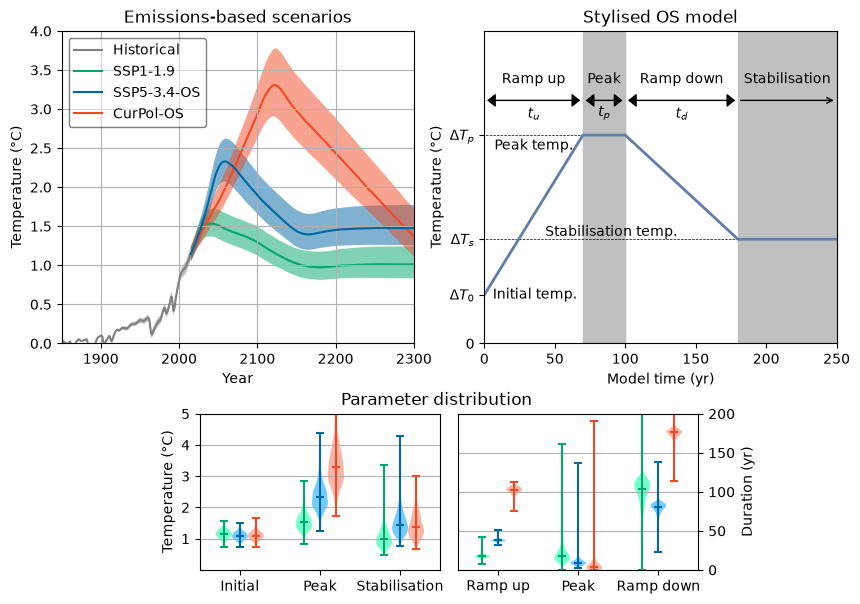

In [58]:
fig = plt.figure(figsize=(10,7))
gs = GridSpec(2,2, figure=fig,hspace=0.3,wspace=0.2,height_ratios=[1,0.5])
# gs1 =  mpl.gridspec.GridSpecFromSubplotSpec(1,2,subplot_spec=gs[0,0],hspace=0.0,wspace=0.18)

# Emnissions-based scenarios
ax_scen = fig.add_subplot(gs[0,0])
ax_scen.set_xlim(1850,2300)
ax_scen.set_ylim(0,4)
illustrative_fig.scenarios_panel(fig,ax_scen,legend_title='',legend_alpha=0.5)
ax_scen.set_ylabel('Temperature (°C)')
ax_scen.set_xlabel("Year")
# ax_scen.yaxis.tick_right()
# ax_scen.yaxis.set_label_position('right')
ax_scen.grid()
ax_scen.set_title('Emissions-based scenarios')

# Stylised OS model
ax_model = fig.add_subplot(gs[0,1])
ax_model.set_xlim(0,250)
ax_model.set_ylim(0.5,5)
illustrative_fig.stylisedOS_panel(fig,ax_model,
                                  stylized_par=(1.2,3.5,2,70,30,80),phase_y=4.2)
ax_model.text(35,3.5-.05,'Peak temp.',ha='center',va='top')
ax_model.text(90,2,'Stabilisation temp.',ha='center',va='bottom')
ax_model.text(0+6,1.2,'Initial temp.',ha='left',va='center')
ax_model.set_yticks([0.5,1.2,2,3.5],[0,r'$\Delta T_0$',r'$\Delta T_s$',r'$\Delta T_p$'])
ax_model.set_title('Stylised OS model')

gs2 = mpl.gridspec.GridSpecFromSubplotSpec(1,4,subplot_spec=gs[1,:],hspace=0.0,wspace=0.1,width_ratios=[0.5,1,1,0.5])
ax_dur = fig.add_subplot(gs2[0,2])#gs[0,1])
ax_tem = fig.add_subplot(gs2[0,1])#gs[1,0])
axs=[ax_tem,ax_dur]
illustrative_fig.parDist_panel(fig,axs,popts)
notation_ticks = ['Initial', 'Peak', 'Stabilisation', 'Ramp up', 'Peak', 'Ramp down']
#[r"$\Delta T_0$", r"$\Delta T_p$", r"$\Delta T_s$", "$t_u$", "$t_p$", "$t_d$"]
for i in range(2):
    axs[i].xaxis.tick_bottom()
    axs[i].set_xlim(-0.5,2.5)
    axs[i].grid(axis='y')
    axs[i].set_xticklabels(notation_ticks[i*3:(i+1)*3])
axs[0].set_ylim(0,5)
axs[0].set_yticks([1,2,3,4,5])
axs[1].set_yticks([0,50,100,150,200])
axs[1].set_ylim(0,200)

fig.text(0.5,0.34,'Parameter distribution',ha='center',fontsize='large',va='bottom')

fig.savefig('../../../Figures/Overshoots/Conference/overshoot_overview.png',bbox_inches='tight',dpi=150,format='png')

In [50]:
for a in axs:
    print(a.get_xlim())

(np.float64(-0.4), np.float64(2.4))
(np.float64(-0.4), np.float64(2.4))
